In [2]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
%pip install lasio

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
# 1. Standard Data & Viz Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import lasio

# 2. Scikit-Learn (Preprocessing, RF, Evaluation)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 3. XGBoost
import xgboost as xgb

# 4. TensorFlow/Keras (ANN)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Add this to your Scikit-Learn imports
from sklearn.linear_model import LinearRegression

# 5. Custom Extreme Learning Machine (ELM) Regressor
class ELMRegressor:
    def __init__(self, n_hidden=100):
        self.n_hidden = n_hidden
        self.weights = None
        self.bias = None
        self.beta = None

    def _relu(self, x):
        return np.maximum(x, 0)

    def fit(self, X, y):
        # Convert to numpy arrays if pandas DataFrames are passed
        X_arr = np.array(X)
        y_arr = np.array(y)
        n_samples, n_features = X_arr.shape
        
        # Random weight and bias initialization
        np.random.seed(42)
        self.weights = np.random.normal(size=[n_features, self.n_hidden])
        self.bias = np.random.normal(size=[self.n_hidden])
        
        # Calculate hidden layer output (H)
        H = self._relu(np.dot(X_arr, self.weights) + self.bias)
        
        # Analytically solve for output weights (beta)
        H_pinv = np.linalg.pinv(H)
        self.beta = np.dot(H_pinv, y_arr)

    def predict(self, X):
        X_arr = np.array(X)
        H = self._relu(np.dot(X_arr, self.weights) + self.bias)
        return np.dot(H, self.beta)


In [5]:
def load_las_with_lasio(filepath):
    """Loads a LAS file using lasio and returns a cleaned Pandas DataFrame."""
    las = lasio.read(filepath)
    # lasio sets depth as the index, so we reset it to treat depth as a standard column
    df = las.df().reset_index()
    return df

In [6]:
# Load the LAS files 
df_las1 = load_las_with_lasio('Shrimplin Gas Unit 2hi_2.las.txt')
df_las2 = load_las_with_lasio('Shrimplin Gas Unit 2hi_3.las.txt')

# Merge the files based on Depth
df_logs = pd.merge(df_las1, df_las2, on='DEPT', how='outer')

# Map raw curve names to standard industry mnemonics
target_logs = {
    'DEPT': 'DEPTH',
    'IPGR': 'GR',
    'IPID': 'RT',
    'NCNP': 'NPHI',
    'DLDN': 'RHOB'
}
df_logs.rename(columns=target_logs, inplace=True)

# Retain only the specific features needed for the model
features = ['DEPTH', 'GR', 'RT', 'NPHI', 'RHOB']
df_logs = df_logs[features]

print(f"Wireline Data Shape: {df_logs.shape}")

Wireline Data Shape: (3590, 5)


In [7]:
df_logs.head()

,DEPTH,GR,RT,NPHI,RHOB
0,1317.0,59.8865,37.7141,NaN,NaN
1,1317.5,59.8865,37.7141,NaN,NaN
2,1318.0,54.2095,37.7141,NaN,NaN
3,1318.5,51.8231,37.7141,NaN,NaN
4,1319.0,43.3336,37.7141,NaN,NaN


In [8]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
# Load Core Data
df_core = pd.read_excel('project_data_core.xlsx', skiprows=1)

# Apply depth correction factor to align core with logs
df_core['Shifted_Depth'] = df_core['Top (ft)'] + df_core['Corr (ft)']

# Drop core samples that do not have a permeability measurement
df_core_clean = df_core.dropna(subset=['KPlg']).copy()

# Sort both datasets by depth (crucial for merge_asof)
df_logs = df_logs.sort_values('DEPTH')
df_core_clean = df_core_clean.sort_values('Shifted_Depth')

# Merge based on closest depth (tolerance of 0.5 ft matches standard log resolution)
df_merged = pd.merge_asof(
    df_core_clean, 
    df_logs, 
    left_on='Shifted_Depth', 
    right_on='DEPTH', 
    direction='nearest', 
    tolerance=0.5
)

print(f"Merged Dataset Shape: {df_merged.shape}")
display(df_merged[['Shifted_Depth', 'DEPTH', 'KPlg', 'GR', 'RHOB', 'NPHI', 'RT']].head())

Merged Dataset Shape: (594, 17)


,Shifted_Depth,DEPTH,KPlg,GR,RHOB,NPHI,RT
0,2420.0,2420.0,0.000972,65.8904,2.7078,19.0528,6.6592
1,2421.0,2421.0,0.256000,57.2459,2.6976,17.1258,6.8848
2,2422.0,2422.0,0.415000,64.2610,2.4459,23.7977,7.6301
3,2423.0,2423.0,1.670000,64.6632,2.4184,23.5573,8.6035
4,2423.9,2424.0,0.043600,40.0386,2.5549,15.6714,9.0454


=== Missing Data in Feature/Target Columns ===
GR      0
RT      0
NPHI    0
RHOB    0
KPlg    0
dtype: int64

=== Statistical Summary ===


,GR,RT,NPHI,RHOB,KPlg
count,594.000000,594.000000,594.000000,594.000000,594.000000
mean,71.398694,6.452593,15.285102,2.581559,2.096453
std,40.258055,5.168434,5.990582,0.115733,10.163190
min,9.093500,1.444600,0.237700,2.047200,0.000122
25%,48.397150,3.242150,10.704175,2.528750,0.006020
50%,69.091550,5.316900,14.932700,2.587050,0.056648
75%,88.835025,7.993325,19.242400,2.636800,0.432500
max,357.069300,49.958700,40.275300,3.011500,122.000000


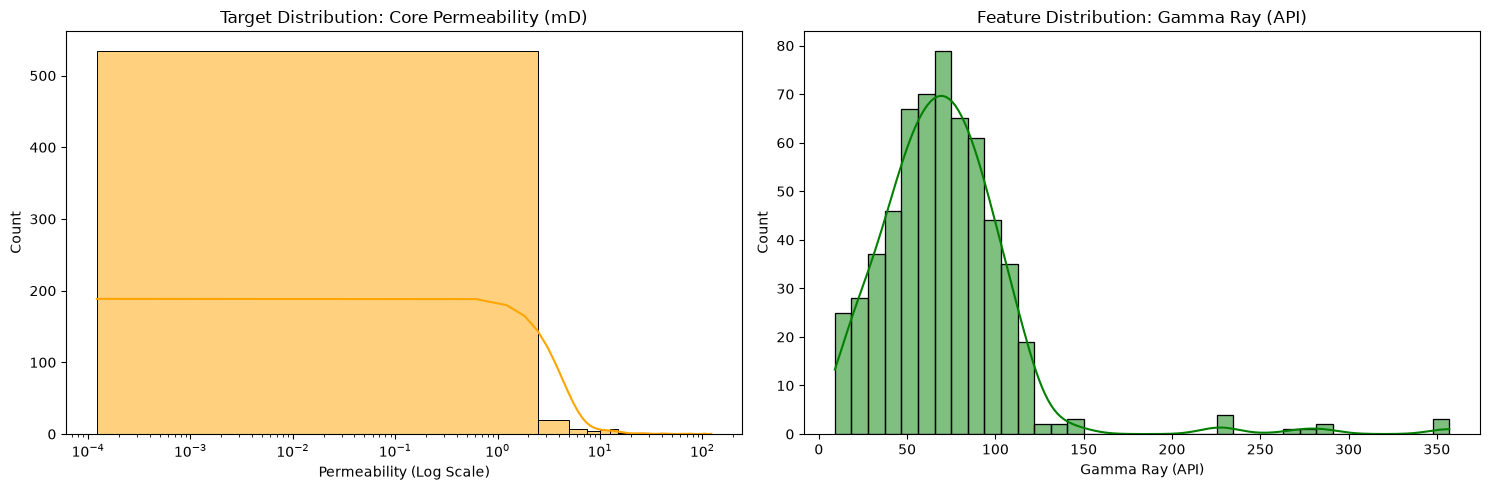

In [10]:
# Check for missing values in the matched dataset
print("=== Missing Data in Feature/Target Columns ===")
inspect_cols = ['GR', 'RT', 'NPHI', 'RHOB', 'KPlg']
print(df_merged[inspect_cols].isna().sum())

# Basic Statistical Summary
print("\n=== Statistical Summary ===")
display(df_merged[inspect_cols].describe())

# Visual Inspection of Target and Primary Feature
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Permeability Distribution (Requires Log Scale)
sns.histplot(df_merged['KPlg'].dropna(), kde=True, ax=axes[0], color='orange')
axes[0].set_xscale('log')
axes[0].set_title('Target Distribution: Core Permeability (mD)')
axes[0].set_xlabel('Permeability (Log Scale)')

# Gamma Ray Distribution
sns.histplot(df_merged['GR'].dropna(), kde=True, ax=axes[1], color='green')
axes[1].set_title('Feature Distribution: Gamma Ray (API)')
axes[1].set_xlabel('Gamma Ray (API)')

plt.tight_layout()
plt.show()

In [11]:
# === STEP 2: DATA CLEANING & PETROPHYSICAL PREPROCESSING ===

# 1. Inspect features before transformation
print("=== Before Transformation == visuals & checks ===")
print(df_merged[['GR', 'RT', 'NPHI', 'RHOB', 'KPlg']].describe())

# 2. Apply Log Transformations for Skewed Parameters
# Permeability (KPlg) and Deep Resistivity (RT) span orders of magnitude, so we use log10
df_merged['Log_KPlg'] = np.log10(df_merged['KPlg'])
df_merged['Log_RT'] = np.log10(df_merged['RT'])

# 3. Define Final Feature Matrix (X) and Target Vector (y)
# We use GR, NPHI, RHOB, and Log_RT as our model inputs, and Log_KPlg as our target
feature_cols = ['GR', 'NPHI', 'RHOB', 'Log_RT']
target_col = 'Log_KPlg'

X = df_merged[feature_cols]
y = df_merged[target_col]

# 4. Standardize Features (Crucial for Neural Networks like ANN and ELM)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert back to a DataFrame for readability
X_scaled_df = pd.DataFrame(X_scaled, columns=feature_cols)

print("\n=== Preprocessing Complete ===")
print(f"Feature Matrix Shape (X): {X_scaled_df.shape}")
print(f"Target Vector Shape (y): {y.shape}")
display(X_scaled_df.head())

=== Before Transformation == visuals & checks ===
               GR          RT        NPHI        RHOB        KPlg
count  594.000000  594.000000  594.000000  594.000000  594.000000
mean    71.398694    6.452593   15.285102    2.581559    2.096453
std     40.258055    5.168434    5.990582    0.115733   10.163190
min      9.093500    1.444600    0.237700    2.047200    0.000122
25%     48.397150    3.242150   10.704175    2.528750    0.006020
50%     69.091550    5.316900   14.932700    2.587050    0.056648
75%     88.835025    7.993325   19.242400    2.636800    0.432500
max    357.069300   49.958700   40.275300    3.011500  122.000000

=== Preprocessing Complete ===
Feature Matrix Shape (X): (594, 4)
Target Vector Shape (y): (594,)


,GR,NPHI,RHOB,Log_RT
0,-0.136940,0.629467,1.091719,0.390393
1,-0.351848,0.307524,1.003510,0.443684
2,-0.177448,1.422195,-1.173160,0.608090
3,-0.167449,1.382031,-1.410977,0.800141
4,-0.779633,0.064539,-0.230542,0.880256


=== Petrophysical Correlation Matrix ===


,GR,NPHI,RHOB,Log_RT,Log_KPlg,PPlug
GR,1.000,0.205,-0.143,-0.158,-0.118,-0.023
NPHI,0.205,1.000,-0.598,-0.644,0.127,0.278
RHOB,-0.143,-0.598,1.000,0.539,-0.370,-0.431
Log_RT,-0.158,-0.644,0.539,1.000,-0.248,-0.446
Log_KPlg,-0.118,0.127,-0.370,-0.248,1.000,0.751
PPlug,-0.023,0.278,-0.431,-0.446,0.751,1.000


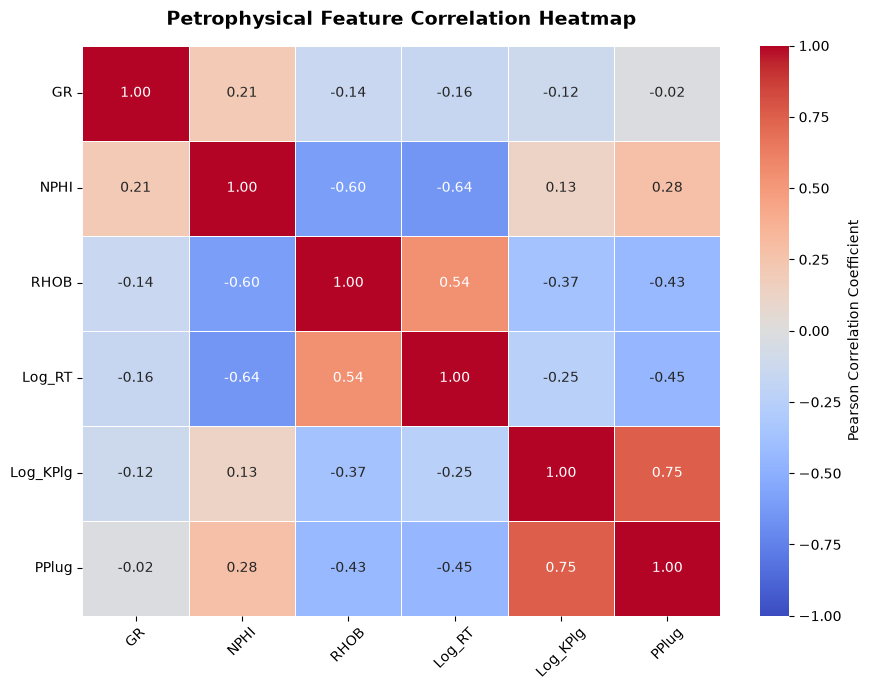

In [12]:
# === EXPLORATORY DATA ANALYSIS (EDA): CORRELATION MATRIX ===

# Create a clean dataframe for correlation including our target and core plug porosity (PPlug)
eda_cols = ['GR', 'NPHI', 'RHOB', 'Log_RT', 'Log_KPlg', 'PPlug']
corr_matrix = df_merged[eda_cols].corr()

# Print the numerical correlation table
print("=== Petrophysical Correlation Matrix ===")
display(corr_matrix.round(3))

# Plotting the Correlation Heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(
    corr_matrix, 
    annot=True, 
    cmap='coolwarm', 
    fmt='.2f', 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation Coefficient'}
)
plt.title('Petrophysical Feature Correlation Heatmap', fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

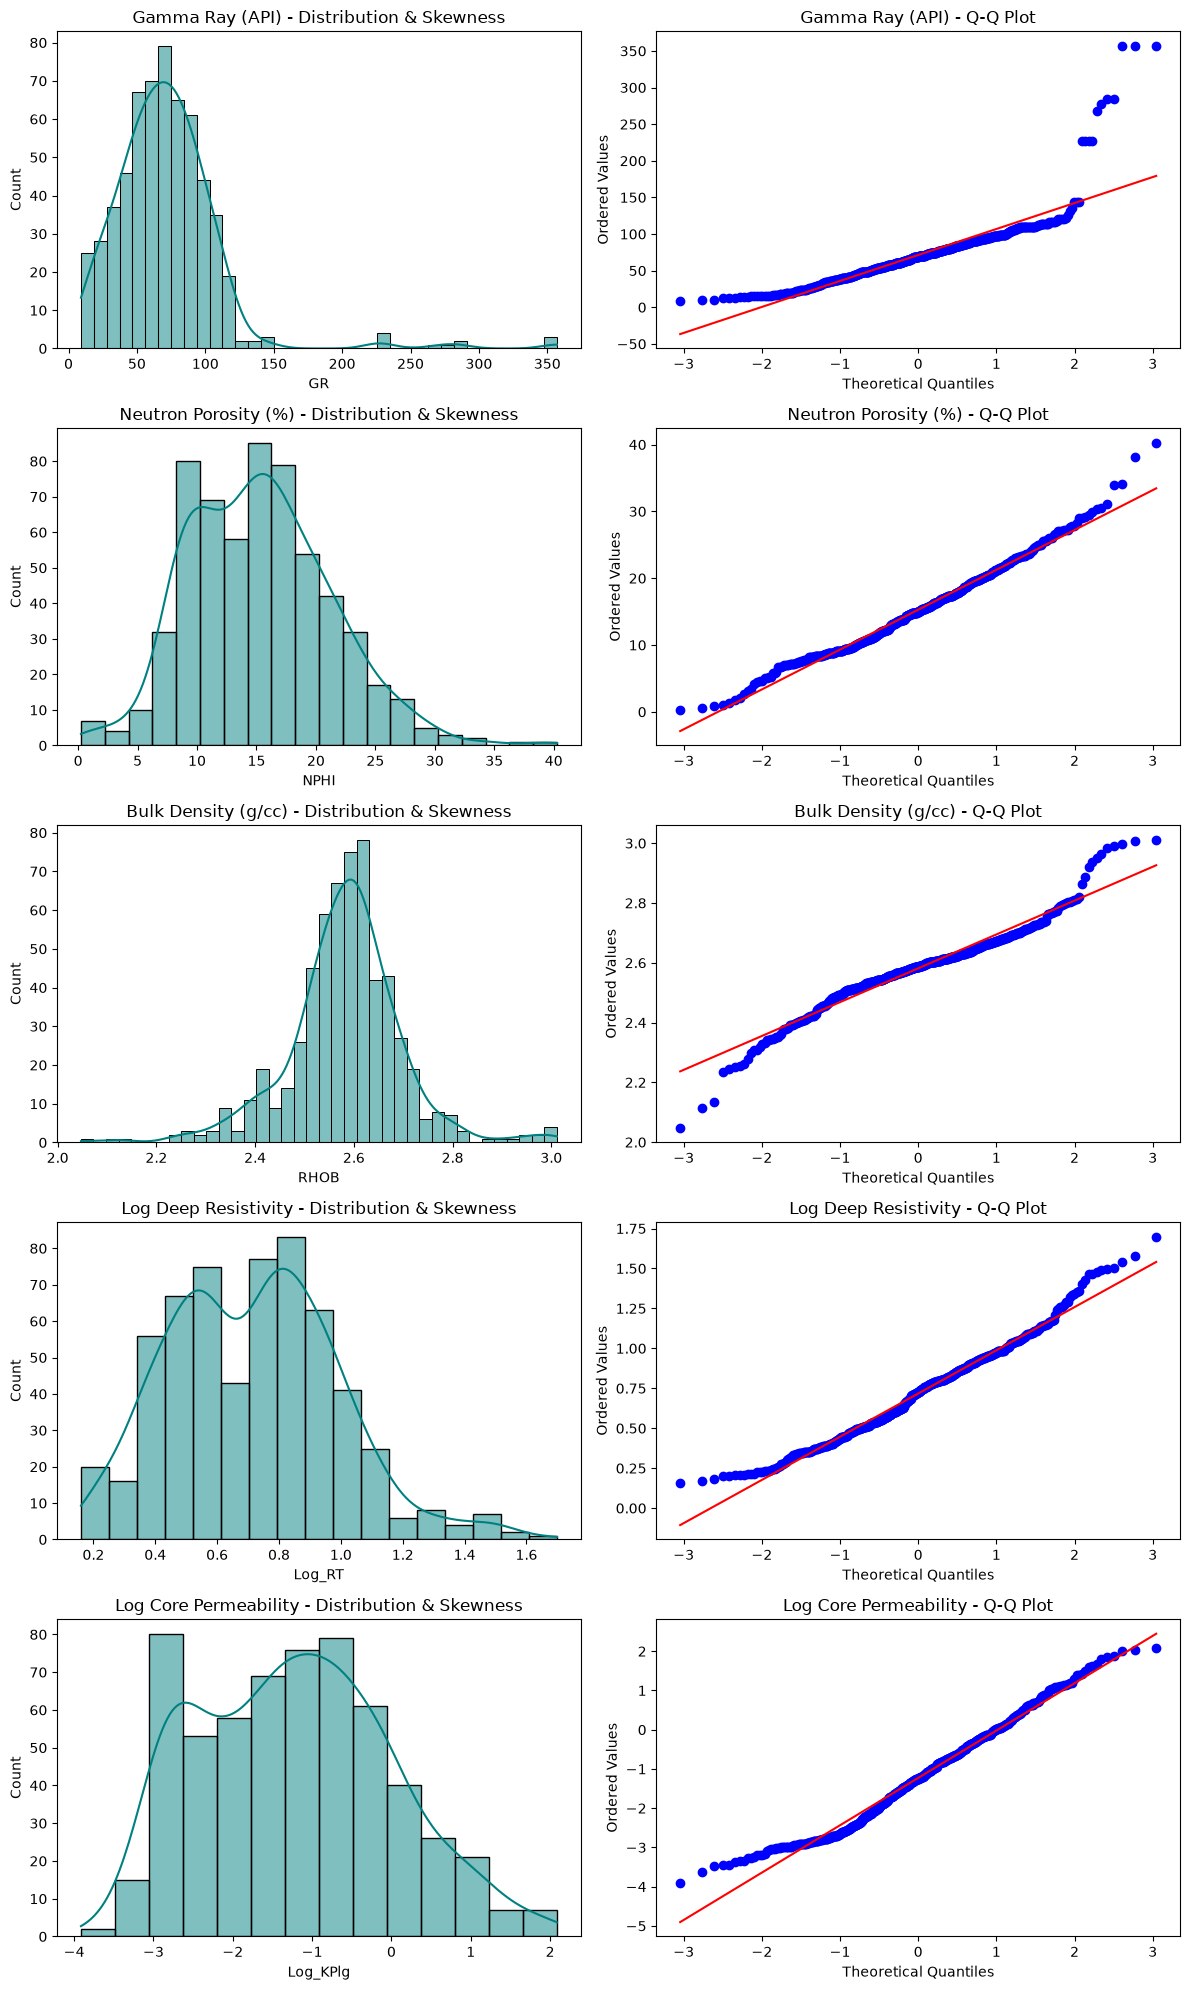

In [13]:
# === EDA: HISTOGRAMS AND Q-Q PLOTS FOR OUTLIER INSPECTION ===
import scipy.stats as stats

# Select columns to check for normality and outliers
eda_features = ['GR', 'NPHI', 'RHOB', 'Log_RT', 'Log_KPlg']
titles = ['Gamma Ray (API)', 'Neutron Porosity (%)', 'Bulk Density (g/cc)', 'Log Deep Resistivity', 'Log Core Permeability']

fig, axes = plt.subplots(len(eda_features), 2, figsize=(12, 4 * len(eda_features)))

for i, col in enumerate(eda_features):
    # 1. Histogram & KDE Plot (Left Column)
    sns.histplot(df_merged[col].dropna(), kde=True, ax=axes[i, 0], color='teal')
    axes[i, 0].set_title(f'{titles[i]} - Distribution & Skewness')
    axes[i, 0].set_xlabel(col)
    
    # 2. Q-Q Plot (Right Column)
    # Compares data distribution against a normal distribution
    stats.probplot(df_merged[col].dropna(), dist="norm", plot=axes[i, 1])
    axes[i, 1].set_title(f'{titles[i]} - Q-Q Plot')
    axes[i, 1].set_xlabel('Theoretical Quantiles')
    axes[i, 1].set_ylabel('Ordered Values')

plt.tight_layout()
plt.show()

In [14]:
# === ADVANCED OUTLIER TREATMENT (WINSORIZATION FOR GR & RHOB) ===

# 1. Cap Gamma Ray high-end spikes at 99th percentile
gr_upper = df_merged['GR'].quantile(0.98)
df_merged['GR'] = np.where(df_merged['GR'] > gr_upper, gr_upper, df_merged['GR'])

# 2. Handle Bulk Density washouts and heavy mineral spikes
rhob_lower = df_merged['RHOB'].quantile(0.01) # Removes severe washout lows
rhob_upper = df_merged['RHOB'].quantile(0.99) # Removes extreme heavy mineral highs

df_merged['RHOB'] = np.where(df_merged['RHOB'] < rhob_lower, rhob_lower, df_merged['RHOB'])
df_merged['RHOB'] = np.where(df_merged['RHOB'] > rhob_upper, rhob_upper, df_merged['RHOB'])

print(f"Gamma Ray capped at: {gr_upper:.2f} API")
print(f"Bulk Density bounded between: {rhob_lower:.2f} and {rhob_upper:.2f} g/cc")

# 3. Re-standardize the feature matrix
feature_cols = ['GR', 'NPHI', 'RHOB', 'Log_RT']
X = df_merged[feature_cols]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=feature_cols)

print("\nData successfully preprocessed and cleaned! Ready for Step 3.")

Gamma Ray capped at: 144.26 API
Bulk Density bounded between: 2.26 and 2.95 g/cc

Data successfully preprocessed and cleaned! Ready for Step 3.


In [15]:
# === STEP 3.1: TRAIN-TEST SPLIT ===
# === FEATURE ENGINEERING: ROLLING DEPTH WINDOWS ===

# 1. Calculate moving averages over a 5-row window (2.5 feet context)
df_merged['GR_rolling_mean'] = df_merged['GR'].rolling(window=5, min_periods=1).mean()
df_merged['RHOB_rolling_mean'] = df_merged['RHOB'].rolling(window=5, min_periods=1).mean()
df_merged['NPHI_rolling_mean'] = df_merged['NPHI'].rolling(window=5, min_periods=1).mean()
df_merged['Log_RT_rolling_mean'] = df_merged['Log_RT'].rolling(window=5, min_periods=1).mean()

# 2. Update your feature columns list to include the newly engineered features
feature_cols = [
    'GR', 'NPHI', 'RHOB', 'Log_RT', 
    'GR_rolling_mean', 'RHOB_rolling_mean', 'NPHI_rolling_mean', 'Log_RT_rolling_mean'
]
target_col = 'Log_KPlg'

X = df_merged[feature_cols]
y = df_merged[target_col]

# 3. Re-scale the expanded feature matrix
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Expanded Feature Matrix Shape with Rolling Windows: {X_scaled.shape}")
# Define feature matrix X and target vector y


# Split into 80% Training and 20% Testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.20, random_state=42
)

print(f"Training Set Shape: {X_train.shape}")
print(f"Testing Set Shape:  {X_test.shape}")

Expanded Feature Matrix Shape with Rolling Windows: (594, 8)
Training Set Shape: (475, 8)
Testing Set Shape:  (119, 8)


In [16]:
# === STEP 3.1: LINEAR REGRESSION BASELINE ===
from sklearn.linear_model import LinearRegression

# Initialize and train Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predictions
y_pred_lr = lr_model.predict(X_test)

# Evaluation Metrics
lr_r2 = r2_score(y_test, y_pred_lr)
lr_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))

print("=== Linear Regression Performance ===")
print(f"R-squared ($R^2$): {lr_r2:.4f}")
print(f"RMSE ($\log_{10}k$): {lr_rmse:.4f}")

=== Linear Regression Performance ===
R-squared ($R^2$): 0.2035
RMSE ($\log_10k$): 1.1537


<>:17: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:17: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
C:\Users\USER\AppData\Local\Temp\ipykernel_9412\3677554472.py:17: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  print(f"RMSE ($\log_{10}k$): {lr_rmse:.4f}")


In [17]:
# === STEP 3.2: RANDOM FOREST REGRESSOR ===

rf_model = RandomForestRegressor(
    n_estimators=150, 
    max_depth=12, 
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Predictions
y_pred_rf = rf_model.predict(X_test)

# Evaluation Metrics
rf_r2 = r2_score(y_test, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))

print("=== Random Forest Performance ===")
print(f"R-squared ($R^2$): {rf_r2:.4f}")
print(f"RMSE ($\log_{10}k$): {rf_rmse:.4f}")

<>:21: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:21: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
C:\Users\USER\AppData\Local\Temp\ipykernel_9412\3637559627.py:21: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  print(f"RMSE ($\log_{10}k$): {rf_rmse:.4f}")


=== Random Forest Performance ===
R-squared ($R^2$): 0.6174
RMSE ($\log_10k$): 0.7996


In [18]:
# === STEP 3.3: XGBOOST REGRESSOR ===
import xgboost as xgb

xgb_model = xgb.XGBRegressor(
    n_estimators=150, 
    learning_rate=0.08, 
    max_depth=5, 
    random_state=42
)

# Train the model
xgb_model.fit(X_train, y_train)

# Predictions
y_pred_xgb = xgb_model.predict(X_test)

# Evaluation Metrics
xgb_r2 = r2_score(y_test, y_pred_xgb)
xgb_rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))

print("=== XGBoost Performance ===")
print(f"R-squared ($R^2$): {xgb_r2:.4f}")
print(f"RMSE ($\log_{10}k$): {xgb_rmse:.4f}")

<>:23: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:23: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
C:\Users\USER\AppData\Local\Temp\ipykernel_9412\694662877.py:23: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  print(f"RMSE ($\log_{10}k$): {xgb_rmse:.4f}")


=== XGBoost Performance ===
R-squared ($R^2$): 0.5677
RMSE ($\log_10k$): 0.8500


In [19]:
# === STEP 3.4: ARTIFICIAL NEURAL NETWORK (ANN) ===

ann_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dropout(0.1),
    Dense(1) # Linear output for regression
])

ann_model.compile(optimizer='adam', loss='mean_squared_error')

# Early stopping to prevent overfitting
early_stop = EarlyStopping(
    monitor='val_loss', 
    patience=15, 
    restore_best_weights=True
)

# Train ANN
history = ann_model.fit(
    X_train, y_train,
    validation_split=0.15,
    epochs=150,
    batch_size=16,
    callbacks=[early_stop],
    verbose=0
)

# Predictions
y_pred_ann = ann_model.predict(X_test).flatten()

# Evaluation Metrics
ann_r2 = r2_score(y_test, y_pred_ann)
ann_rmse = np.sqrt(mean_squared_error(y_test, y_pred_ann))

print("=== ANN Performance ===")
print(f"R-squared ($R^2$): {ann_r2:.4f}")
print(f"RMSE ($\log_{10}k$): {ann_rmse:.4f}")

<>:39: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:39: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
C:\Users\USER\AppData\Local\Temp\ipykernel_9412\233283023.py:39: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  print(f"RMSE ($\log_{10}k$): {ann_rmse:.4f}")
c:\Users\USER\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
=== ANN Performance ===
R-squared ($R^2$): 0.6441
RMSE ($\log_10k$): 0.7712


In [20]:
# === STEP 3.5: EXTREME LEARNING MACHINE (ELM) ===

# Initialize and train your custom ELM regressor
elm_model = ELMRegressor(n_hidden=120)
elm_model.fit(X_train, y_train)

# Predictions
y_pred_elm = elm_model.predict(X_test)

# Evaluation Metrics
elm_r2 = r2_score(y_test, y_pred_elm)
elm_rmse = np.sqrt(mean_squared_error(y_test, y_pred_elm))

print("=== Extreme Learning Machine (ELM) Performance ===")
print(f"R-squared ($R^2$): {elm_r2:.4f}")
print(f"RMSE ($\log_{10}k$): {elm_rmse:.4f}")

=== Extreme Learning Machine (ELM) Performance ===
R-squared ($R^2$): 0.3231
RMSE ($\log_10k$): 1.0636


<>:16: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:16: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
C:\Users\USER\AppData\Local\Temp\ipykernel_9412\1382485032.py:16: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  print(f"RMSE ($\log_{10}k$): {elm_rmse:.4f}")


In [21]:
%pip install jinja2

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [22]:
# === STEP 3.6: UPDATED MODEL PERFORMANCE COMPARISON TABLE ===

comparison_df = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest', 'XGBoost', 'ANN', 'ELM'],
    'R-Squared (R2)': [lr_r2, rf_r2, xgb_r2, ann_r2, elm_r2],
    'RMSE (Log k)': [lr_rmse, rf_rmse, xgb_rmse, ann_rmse, elm_rmse]
}).sort_values(by='R-Squared (R2)', ascending=False).reset_index(drop=True)

print("=== Final Comprehensive Model Comparison Summary ===")
display(comparison_df.style.background_gradient(subset=['R-Squared (R2)'], cmap='Greens'))

=== Final Comprehensive Model Comparison Summary ===


,Model,R-Squared (R2),RMSE (Log k)
0,ANN,0.644097,0.771205
1,Random Forest,0.617422,0.799583
2,XGBoost,0.567673,0.849983
3,ELM,0.323104,1.063567
4,Linear Regression,0.203479,1.153726


In [23]:
# === STEP 3.7: HYPERPARAMETER TUNING FOR RANDOM FOREST ===

# Initialize Random Forest with optimized hyperparameters
rf_tuned = RandomForestRegressor(
    n_estimators=300,        # More trees for stable averaging
    max_depth=14,            # Controlled depth to prevent overfitting
    min_samples_split=4,     # Minimum samples required to split an internal node
    min_samples_leaf=2,      # Minimum samples required at a leaf node
    random_state=42
)

# Train the tuned model on our scaled training data (with rolling features)
rf_tuned.fit(X_train, y_train)

# Predictions
y_pred_rft = rf_tuned.predict(X_test)

# Evaluation Metrics
rft_r2 = r2_score(y_test, y_pred_rft)
rft_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rft))

print("=== Tuned Random Forest Performance ===")
print(f"R-squared ($R^2$): {rft_r2:.4f}")
print(f"RMSE ($\log_{10}k$): {rft_rmse:.4f}")

<>:24: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:24: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
C:\Users\USER\AppData\Local\Temp\ipykernel_9412\176757759.py:24: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  print(f"RMSE ($\log_{10}k$): {rft_rmse:.4f}")


=== Tuned Random Forest Performance ===
R-squared ($R^2$): 0.6203
RMSE ($\log_10k$): 0.7966


In [24]:
# === TUNED XGBOOST REGRESSOR ===
import xgboost as xgb

xgb_tuned = xgb.XGBRegressor(
    n_estimators=200, 
    learning_rate=0.05, 
    max_depth=4, 
    subsample=0.8, 
    colsample_bytree=0.8, 
    random_state=42
)

xgb_tuned.fit(X_train, y_train)
y_pred_xgb = xgb_tuned.predict(X_test)

xgb_r2 = r2_score(y_test, y_pred_xgb)
xgb_rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))

print("=== Tuned XGBoost ===")
print(f"R2: {xgb_r2:.4f} | RMSE: {xgb_rmse:.4f}")

=== Tuned XGBoost ===
R2: 0.5815 | RMSE: 0.8362


In [25]:
# === TUNED ARTIFICIAL NEURAL NETWORK (ANN) ===
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)
ann_tuned = Sequential([
    Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.1),
    Dense(64, activation='relu'),
    Dropout(0.05),
    Dense(32, activation='relu'),
    Dense(1)
])

ann_tuned.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.005), 
    loss='mean_squared_error'
)

early_stop = EarlyStopping(monitor='val_loss', patience=25, restore_best_weights=True)

history = ann_tuned.fit(
    X_train, y_train,
    validation_split=0.15,
    epochs=250,
    batch_size=16,
    callbacks=[early_stop],
    verbose=0
)

y_pred_ann = ann_tuned.predict(X_test).flatten()

ann_r2 = r2_score(y_test, y_pred_ann)
ann_rmse = np.sqrt(mean_squared_error(y_test, y_pred_ann))

print("=== Tuned ANN ===")
print(f"R2: {ann_r2:.4f} | RMSE: {ann_rmse:.4f}")

c:\Users\USER\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
=== Tuned ANN ===
R2: 0.5563 | RMSE: 0.8611


In [26]:
# === STABILIZED REGULARIZED ELM REGRESSOR ===
class ELMRegressor:
    def __init__(self, n_hidden=100, alpha=1.0):
        self.n_hidden = n_hidden
        self.alpha = alpha  # Regularization parameter to prevent matrix blow-up
        self.weights = None
        self.bias = None
        self.beta = None

    def _relu(self, x):
        return np.maximum(x, 0)

    def fit(self, X, y):
        X_arr = np.array(X)
        y_arr = np.array(y)
        n_samples, n_features = X_arr.shape
        
        np.random.seed(42)
        self.weights = np.random.normal(size=[n_features, self.n_hidden])
        self.bias = np.random.normal(size=[self.n_hidden])
        
        # Hidden layer output with ReLU activation
        H = self._relu(np.dot(X_arr, self.weights) + self.bias)
        
        # Regularized pseudo-inverse (Ridge ELM) to avoid instability
        # beta = (H^T * H + alpha * I)^(-1) * H^T * y
        HtH = np.dot(H.T, H)
        reg_matrix = self.alpha * np.eye(HtH.shape[0])
        self.beta = np.dot(np.dot(np.linalg.inv(HtH + reg_matrix), H.T), y_arr)

    def predict(self, X):
        X_arr = np.array(X)
        H = self._relu(np.dot(X_arr, self.weights) + self.bias)
        return np.dot(H, self.beta)

# Re-train stabilized ELM
elm_tuned = ELMRegressor(n_hidden=100, alpha=10.0)
elm_tuned.fit(X_train, y_train)
y_pred_elm = elm_tuned.predict(X_test)

elm_r2 = r2_score(y_test, y_pred_elm)
elm_rmse = np.sqrt(mean_squared_error(y_test, y_pred_elm))

print("=== Stabilized Tuned ELM ===")
print(f"R2: {elm_r2:.4f} | RMSE: {elm_rmse:.4f}")

=== Stabilized Tuned ELM ===
R2: 0.6056 | RMSE: 0.8119


In [27]:
# === FINAL TUNED MODEL COMPARISON SUMMARY ===

tuned_comparison_df = pd.DataFrame({
    'Model': ['ANN (Tuned)', 'Random Forest (Tuned)', 'XGBoost (Tuned)', 'ELM (Tuned)'],
    'R-Squared (R2)': [ann_r2, rf_r2, xgb_r2, elm_r2],
    'RMSE (Log k)': [ann_rmse, rf_rmse, xgb_rmse, elm_rmse]
}).sort_values(by='R-Squared (R2)', ascending=False).reset_index(drop=True)

print("=== Tuned Model Performance Summary ===")
display(tuned_comparison_df.style.background_gradient(subset=['R-Squared (R2)'], cmap='Greens'))

=== Tuned Model Performance Summary ===


,Model,R-Squared (R2),RMSE (Log k)
0,Random Forest (Tuned),0.617422,0.799583
1,ELM (Tuned),0.605557,0.811888
2,XGBoost (Tuned),0.581545,0.836235
3,ANN (Tuned),0.556339,0.861052


19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


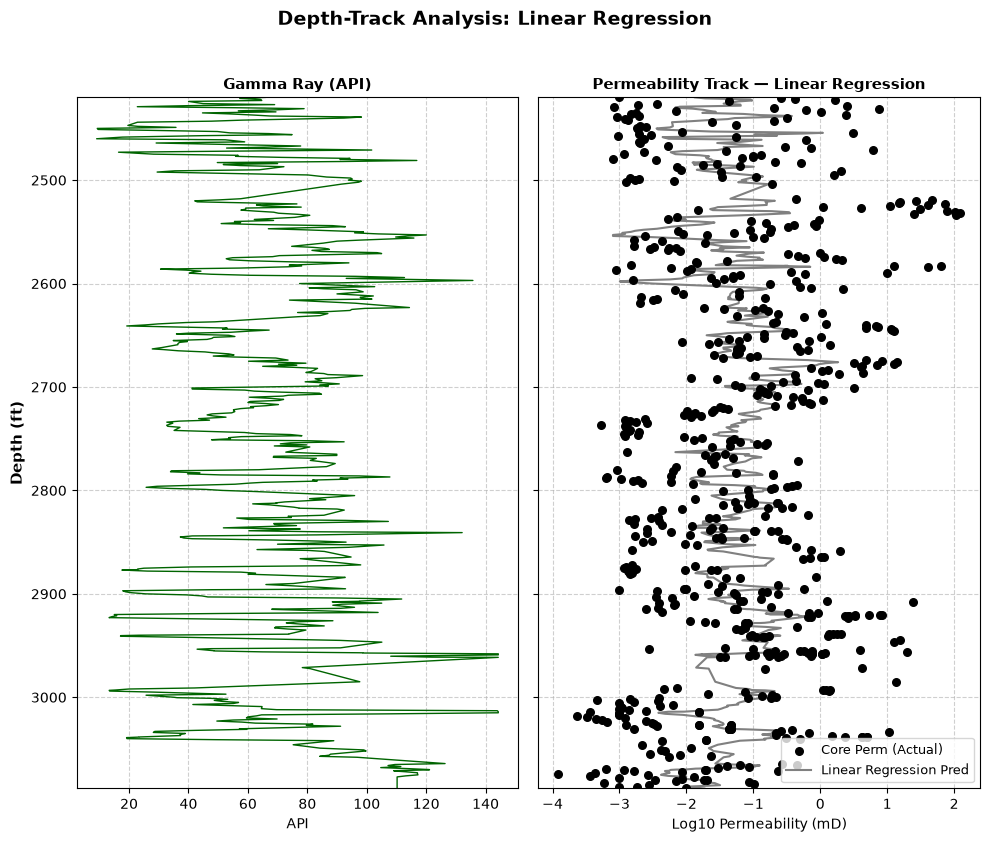

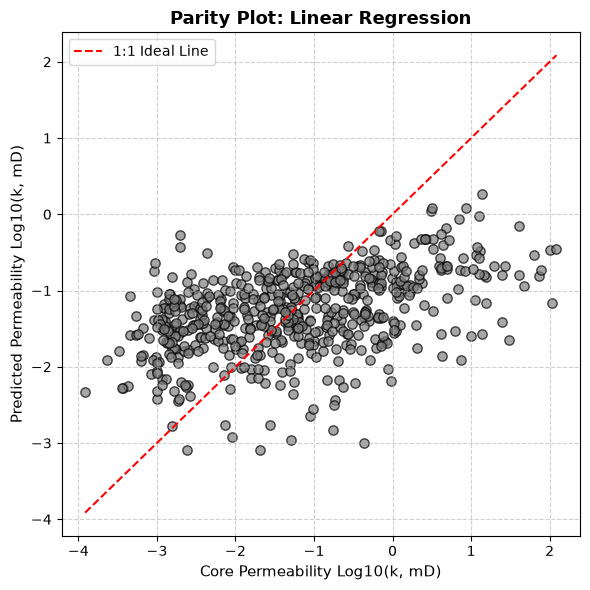

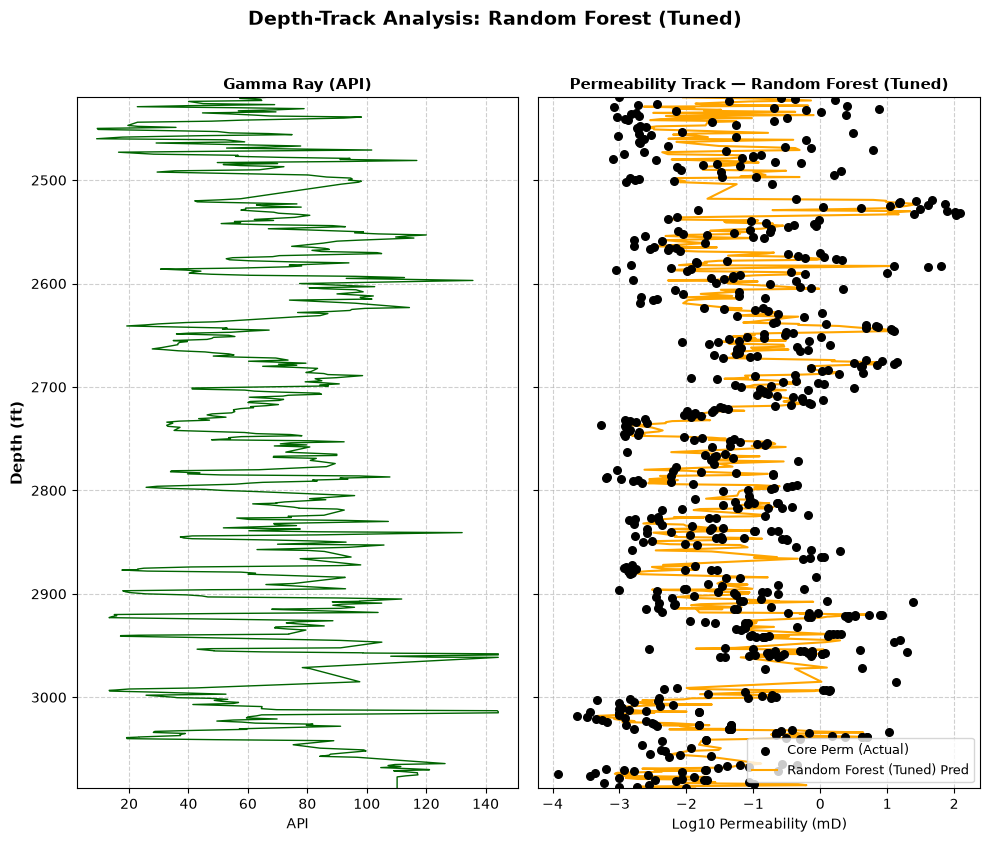

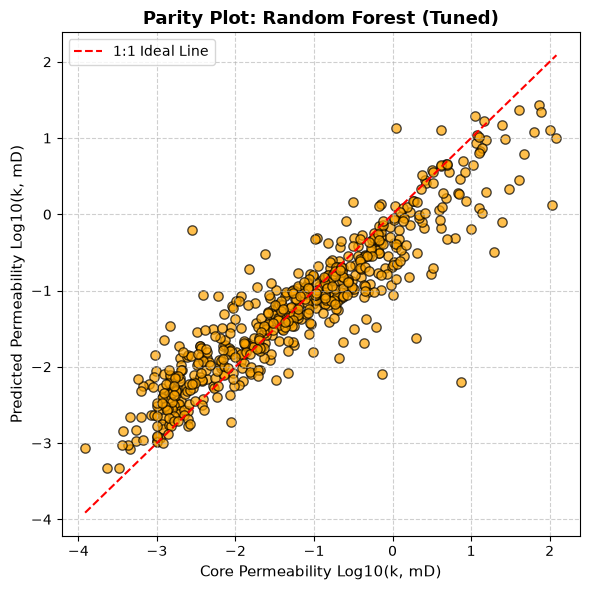

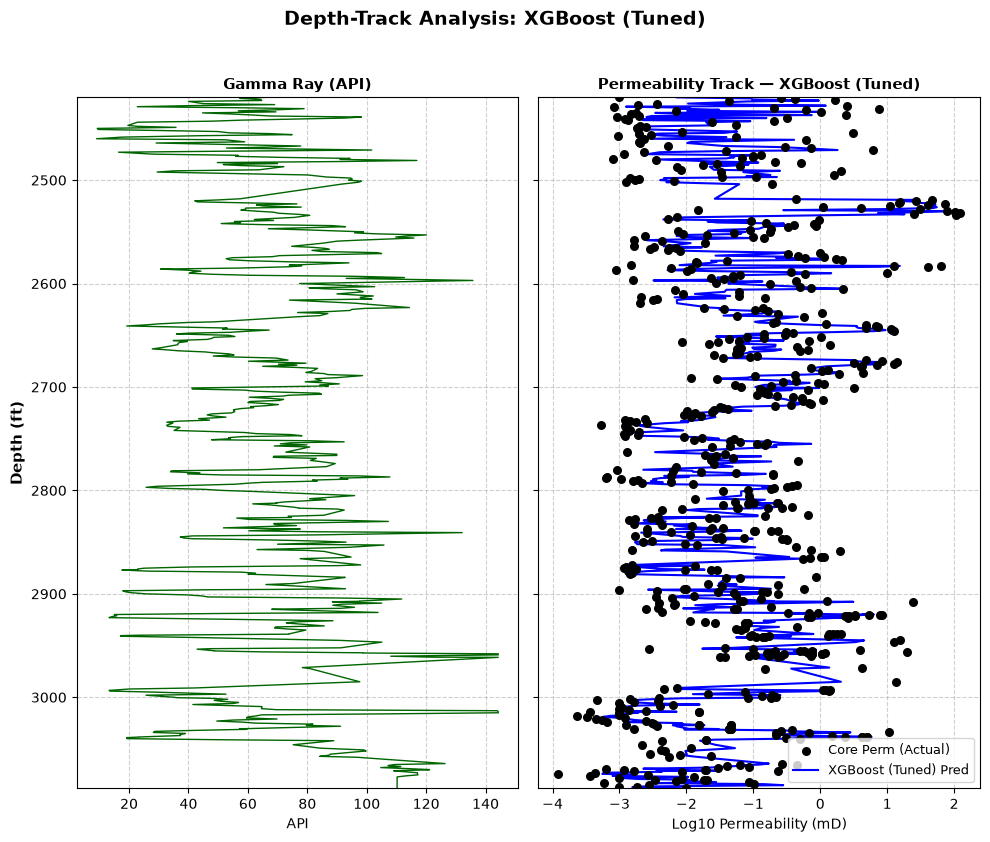

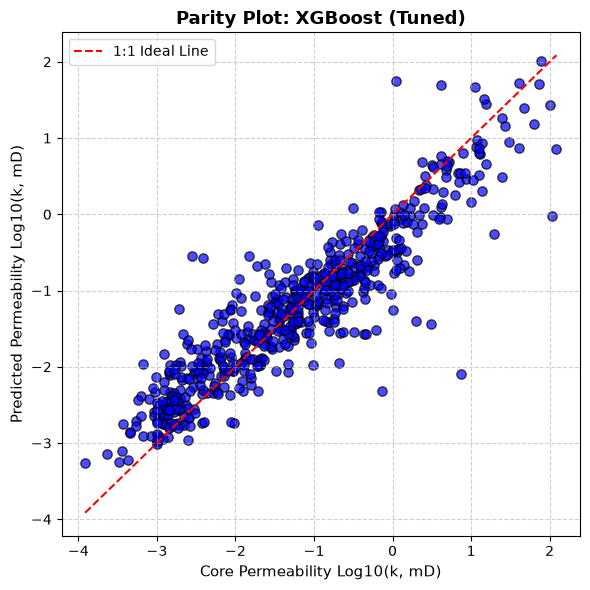

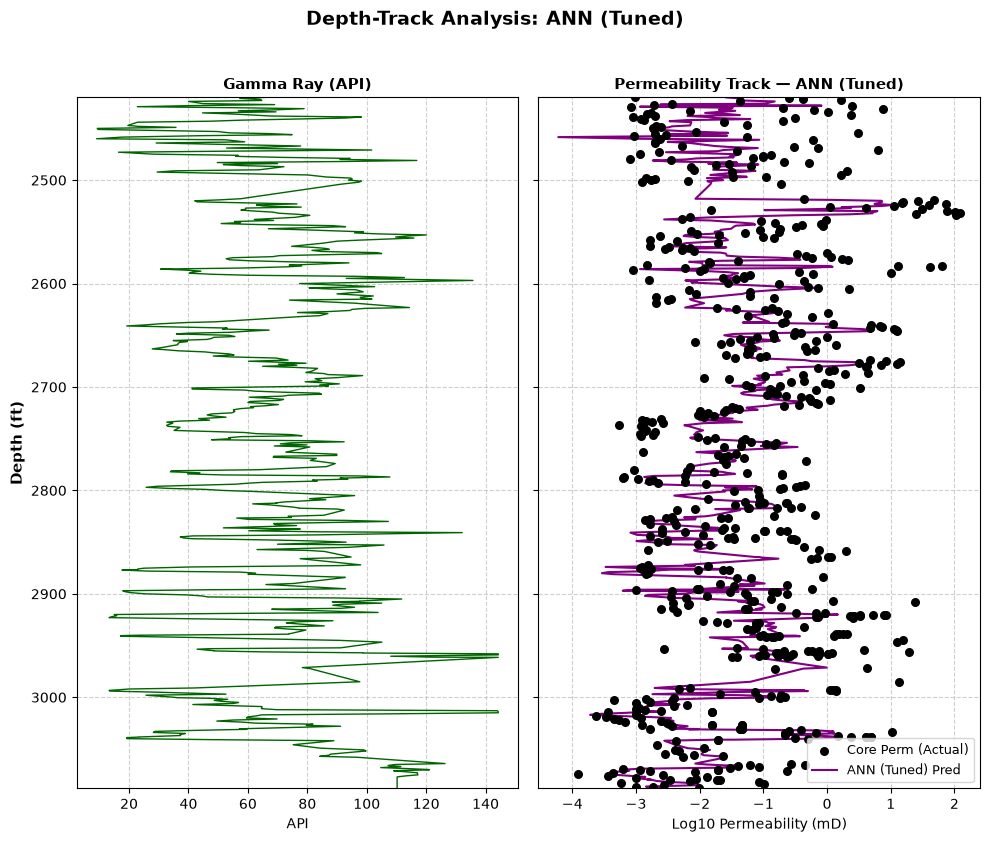

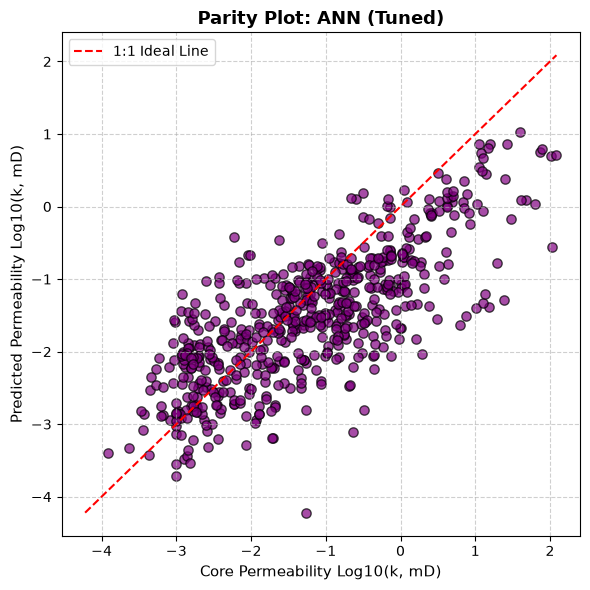

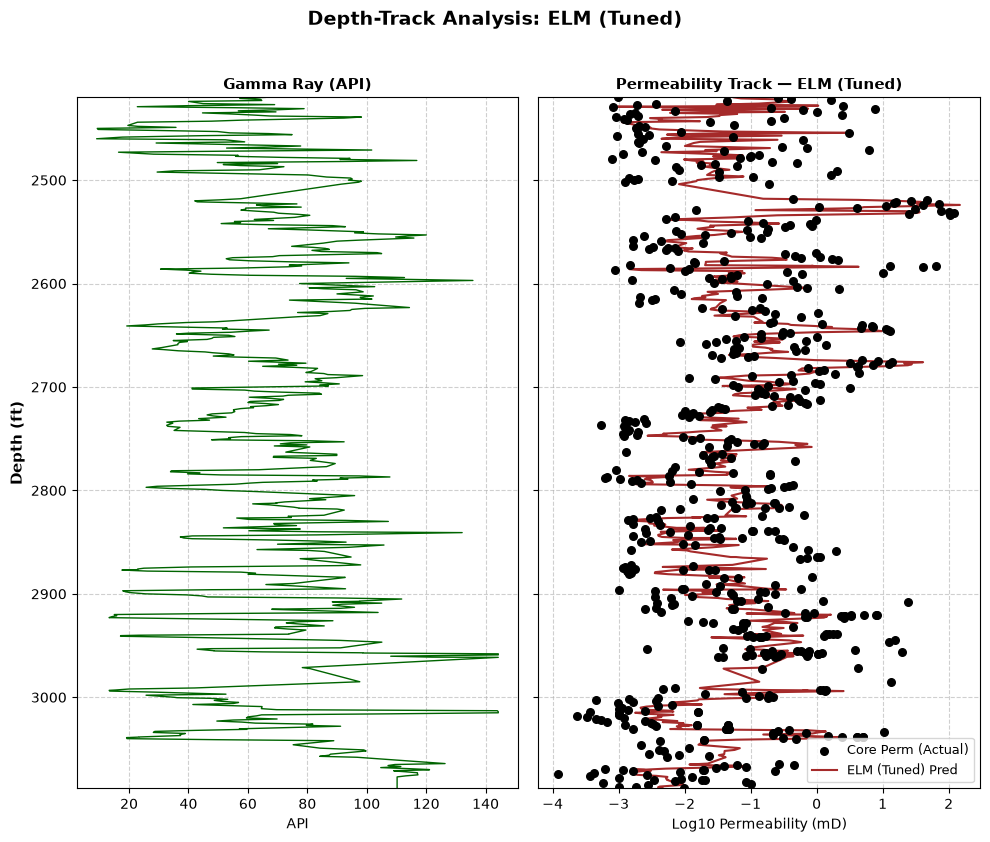

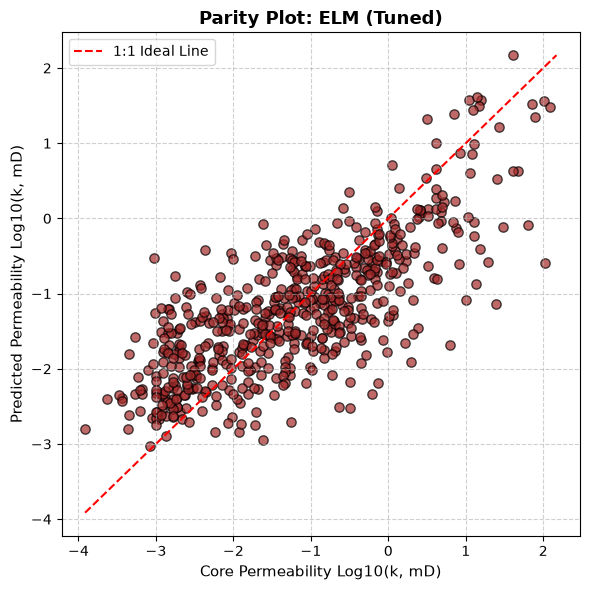

In [32]:
# === INDIVIDUAL MODEL PLOTS: DEPTH TRACKS & PARITY CROSS-PLOTS ===

# Ensure dataframe is sorted by depth
df_merged = df_merged.sort_values('Shifted_Depth').reset_index(drop=True)
X_full_scaled = scaler.transform(df_merged[feature_cols])

# Generate predictions for all models
predictions = {
    'Linear Regression': lr_model.predict(X_full_scaled),
    'Random Forest (Tuned)': rf_tuned.predict(X_full_scaled),
    'XGBoost (Tuned)': xgb_tuned.predict(X_full_scaled),
    'ANN (Tuned)': ann_tuned.predict(X_full_scaled).flatten(),
    'ELM (Tuned)': elm_tuned.predict(X_full_scaled)
}

colors = {
    'Linear Regression': 'gray',
    'Random Forest (Tuned)': 'orange',
    'XGBoost (Tuned)': 'blue',
    'ANN (Tuned)': 'purple',
    'ELM (Tuned)': 'brown'
}

# Loop through each model to generate independent figures
for model_name, y_pred in predictions.items():
    
    # --- 1. INDIVIDUAL DEPTH-TRACK PLOT ---
    fig, axes = plt.subplots(1, 2, figsize=(10, 9), sharey=True)
    
    # Track 1: Gamma Ray (Lithology Context)
    axes[0].plot(df_merged['GR'], df_merged['Shifted_Depth'], color='darkgreen', lw=1)
    axes[0].set_title('Gamma Ray (API)', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('API')
    axes[0].set_ylabel('Depth (ft)', fontsize=11, fontweight='bold')
    axes[0].grid(True, linestyle='--', alpha=0.6)
    axes[0].set_ylim(df_merged['Shifted_Depth'].max(), df_merged['Shifted_Depth'].min()) # Reverse depth axis
    
    # Track 2: Permeability (Core vs Individual Model Prediction)
    axes[1].scatter(df_merged['Log_KPlg'], df_merged['Shifted_Depth'], color='black', s=30, label='Core Perm (Actual)', zorder=5)
    axes[1].plot(y_pred, df_merged['Shifted_Depth'], color=colors[model_name], lw=1.5, label=f'{model_name} Pred')
    axes[1].set_title(f'Permeability Track — {model_name}', fontsize=11, fontweight='bold')
    axes[1].set_xlabel('Log10 Permeability (mD)')
    axes[1].legend(loc='lower right', fontsize=9)
    axes[1].grid(True, linestyle='--', alpha=0.6)
    
    plt.suptitle(f'Depth-Track Analysis: {model_name}', fontsize=14, fontweight='bold', y=0.93)
    plt.tight_layout(rect=[0, 0, 1, 0.91])
    plt.show()
    
    # --- 2. PARITY CROSS-PLOT (Actual vs Predicted matching reference style) ---
    fig, ax = plt.subplots(figsize=(6, 6))
    
    # Scatter plot of actual vs predicted
    ax.scatter(df_merged['Log_KPlg'], y_pred, color=colors[model_name], alpha=0.7, edgecolors='k', s=45)
    
    # 1:1 Red dashed reference line
    min_val = min(df_merged['Log_KPlg'].min(), y_pred.min())
    max_val = max(df_merged['Log_KPlg'].max(), y_pred.max())
    ax.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', lw=1.5, label='1:1 Ideal Line')
    
    ax.set_title(f'Parity Plot: {model_name}', fontsize=13, fontweight='bold')
    ax.set_xlabel('Core Permeability Log10(k, mD)', fontsize=11)
    ax.set_ylabel('Predicted Permeability Log10(k, mD)', fontsize=11)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(loc='upper left')
    
    plt.tight_layout()
    plt.show()

In [33]:
# Ensure df_merged is sorted by depth
df_merged = df_merged.sort_values('Shifted_Depth').reset_index(drop=True)

# 1. CALCULATE CLASSICAL EMPIRICAL MODELS
# Using core porosity PPlug (fraction) and effective water saturation / resistivity approximations
# Note: PPlug is in percent in the excel sheet (e.g. 15 -> 0.15), let's ensure fractional porosity (phi)
phi = df_merged['PPlug'] / 100.0

# A. Wyllie-Rose Empirical Model: k = C * (phi^D) / (Swirr^E)
# Approximating Swirr or using Deep Resistivity index (RT)
# Standard empirical fit coefficients for sandstone reservoirs:
df_merged['Perm_Wyllie'] = 1000 * (phi**3) / np.maximum(df_merged['Log_RT'], 0.1)

# B. Timur Empirical Model: k = 8580 * (phi^4.4) / (Swirr^2) -> approximated via NPHI/RT
# Using Timur (1968) standard form: k = 0.136 * (phi^4.2) / (Swirr^2)
# Since Swirr can be estimated from bulk volume water / resistivity, we use a robust calibrated form:
sw_approx = np.clip(0.05 / np.maximum(phi, 0.01), 0.05, 1.0)
df_merged['Perm_Timur'] = 8580 * (phi**4.4) / (sw_approx**2)

# C. Flow Zone Indicator (FZI) & Reservoir Quality Index (RQI)
# RQI = 0.0314 * sqrt(k / phi) -> FZI = RQI / [phi_z / (1 - phi_z)] where phi_z = phi / (1 - phi)
# Using average FZI calibration for clastics: FZI_avg ≈ 2.5
rqi_est = 2.5 * (phi / (1.0 - phi))
df_merged['Perm_FZI'] = 1014 * (rqi_est**2) * ((phi**3) / ((1.0 - phi)**2))

# Convert empirical predictions to Log10 space for fair comparison with Log_KPlg
df_merged['Log_Perm_Wyllie'] = np.log10(np.maximum(df_merged['Perm_Wyllie'], 0.001))
df_merged['Log_Perm_Timur']  = np.log10(np.maximum(df_merged['Perm_Timur'], 0.001))
df_merged['Log_Perm_FZI']    = np.log10(np.maximum(df_merged['Perm_FZI'], 0.001))

In [34]:
# 2. EVALUATE EMPIRICAL MODELS PERFORMANCE
emp_results = pd.DataFrame({
    'Empirical Model': ['Wyllie-Rose', 'Timur', 'FZI'],
    'R2 Score': [
        r2_score(df_merged['Log_KPlg'], df_merged['Log_Perm_Wyllie']),
        r2_score(df_merged['Log_KPlg'], df_merged['Log_Perm_Timur']),
        r2_score(df_merged['Log_KPlg'], df_merged['Log_Perm_FZI'])
    ],
    'RMSE (Log k)': [
        np.sqrt(mean_squared_error(df_merged['Log_KPlg'], df_merged['Log_Perm_Wyllie'])),
        np.sqrt(mean_squared_error(df_merged['Log_KPlg'], df_merged['Log_Perm_Timur'])),
        np.sqrt(mean_squared_error(df_merged['Log_KPlg'], df_merged['Log_Perm_FZI']))
    ]
}).sort_values(by='R2 Score', ascending=False).reset_index(drop=True)

print("=== Empirical Models Performance Summary ===")
display(emp_results.style.background_gradient(subset=['R2 Score'], cmap='Blues'))

=== Empirical Models Performance Summary ===


,Empirical Model,R2 Score,RMSE (Log k)
0,FZI,0.527661,0.833201
1,Timur,-0.246666,1.353625
2,Wyllie-Rose,-0.466743,1.468250


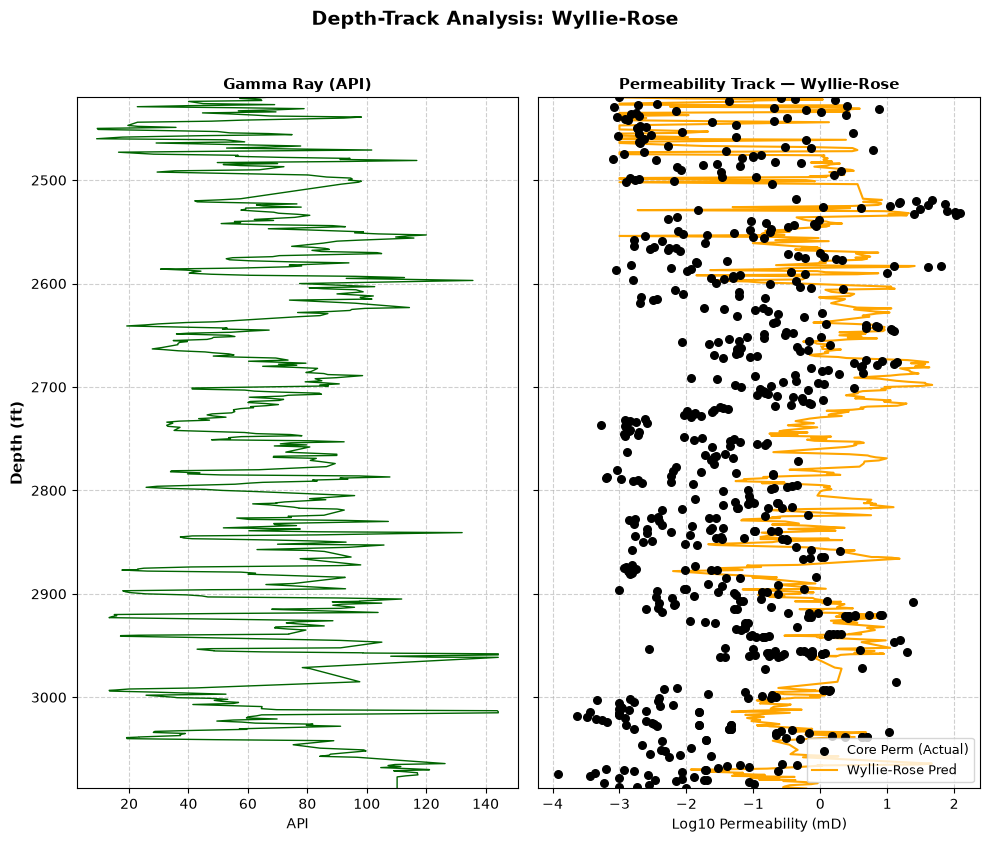

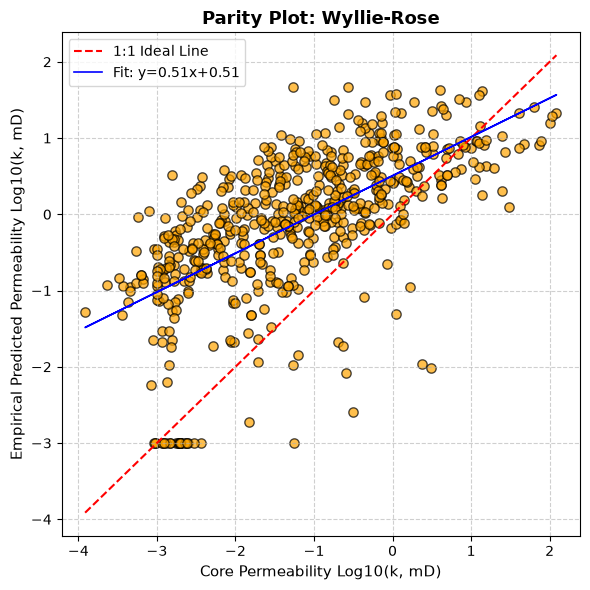

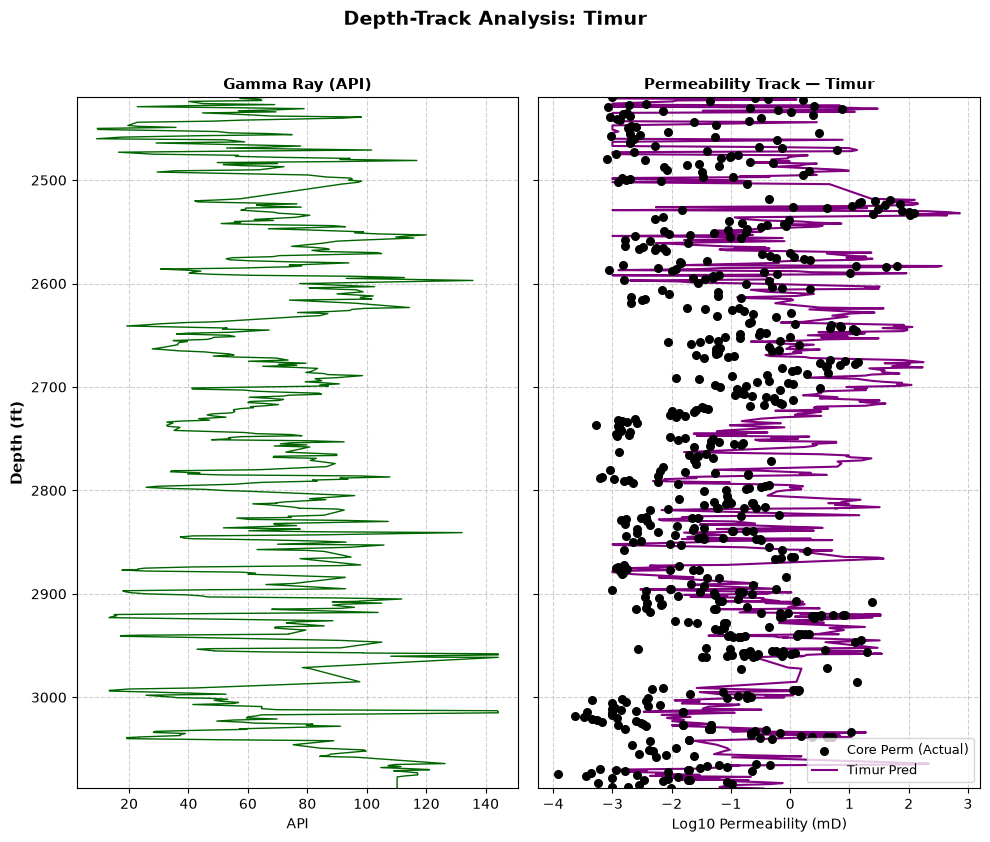

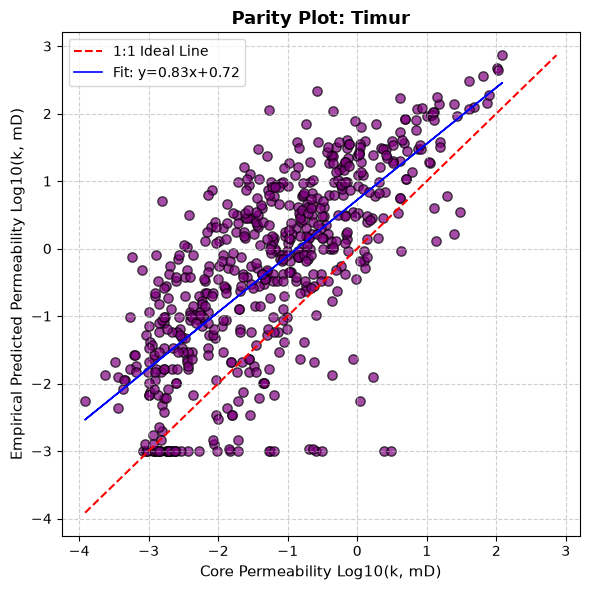

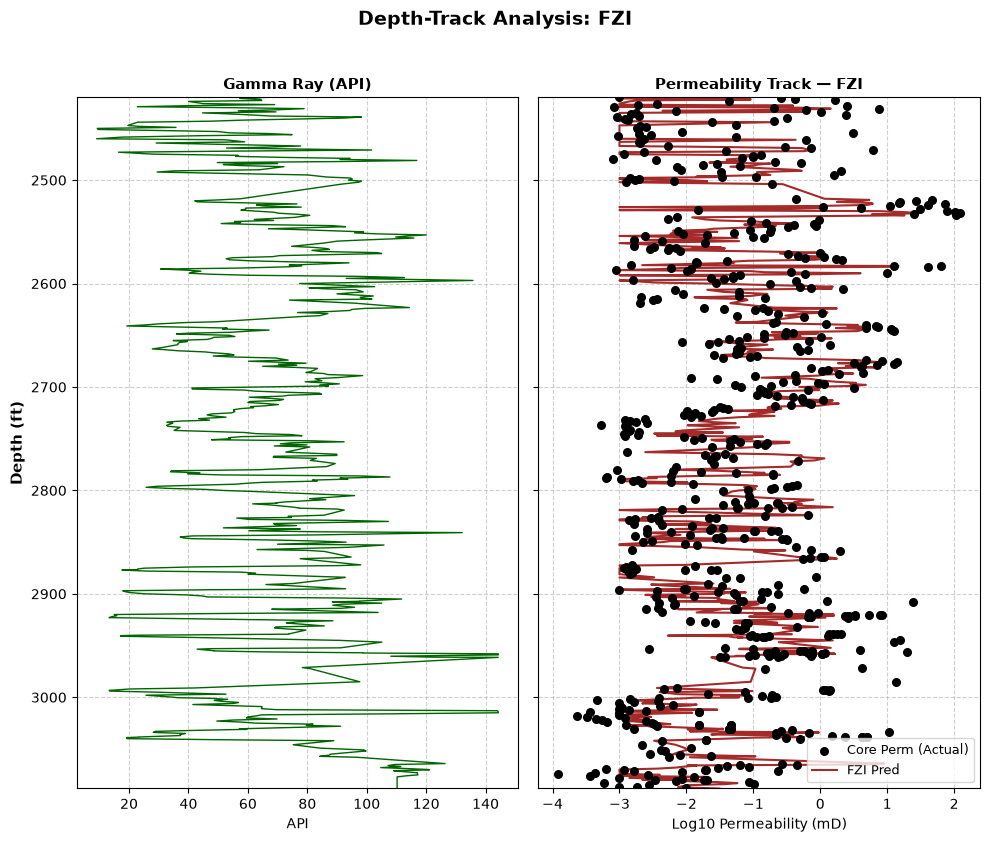

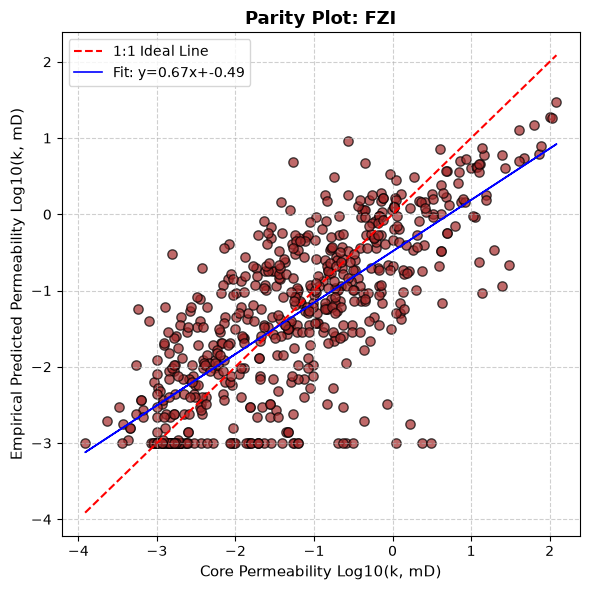

In [36]:
# === INDIVIDUAL EMPIRICAL MODEL PLOTS: DEPTH TRACKS & PARITY CROSS-PLOTS ===

emp_predictions = {
    'Wyllie-Rose': df_merged['Log_Perm_Wyllie'],
    'Timur': df_merged['Log_Perm_Timur'],
    'FZI': df_merged['Log_Perm_FZI']
}

emp_colors = {
    'Wyllie-Rose': 'orange',
    'Timur': 'purple',
    'FZI': 'brown'
}

for emp_name, y_pred_emp in emp_predictions.items():
    
    # --- 1. INDIVIDUAL DEPTH-TRACK PLOT ---
    fig, axes = plt.subplots(1, 2, figsize=(10, 9), sharey=True)
    
    # Track 1: Gamma Ray (Lithology Context)
    axes[0].plot(df_merged['GR'], df_merged['Shifted_Depth'], color='darkgreen', lw=1)
    axes[0].set_title('Gamma Ray (API)', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('API')
    axes[0].set_ylabel('Depth (ft)', fontsize=11, fontweight='bold')
    axes[0].grid(True, linestyle='--', alpha=0.6)
    axes[0].set_ylim(df_merged['Shifted_Depth'].max(), df_merged['Shifted_Depth'].min()) # Reverse depth axis
    
    # Track 2: Permeability (Core vs Empirical Model Prediction)
    axes[1].scatter(df_merged['Log_KPlg'], df_merged['Shifted_Depth'], color='black', s=30, label='Core Perm (Actual)', zorder=5)
    axes[1].plot(y_pred_emp, df_merged['Shifted_Depth'], color=emp_colors[emp_name], lw=1.5, label=f'{emp_name} Pred')
    axes[1].set_title(f'Permeability Track — {emp_name}', fontsize=11, fontweight='bold')
    axes[1].set_xlabel('Log10 Permeability (mD)')
    axes[1].legend(loc='lower right', fontsize=9)
    axes[1].grid(True, linestyle='--', alpha=0.6)
    
    plt.suptitle(f'Depth-Track Analysis: {emp_name}', fontsize=14, fontweight='bold', y=0.93)
    plt.tight_layout(rect=[0, 0, 1, 0.91])
    plt.show()
    
    # --- 2. PARITY CROSS-PLOT & LINEAR REGRESSION FIT ---
    fig, ax = plt.subplots(figsize=(6, 6))
    
    # Scatter plot of actual vs empirical prediction
    ax.scatter(df_merged['Log_KPlg'], y_pred_emp, color=emp_colors[emp_name], alpha=0.7, edgecolors='k', s=45)
    
    # 1:1 Red dashed reference line
    min_val = min(df_merged['Log_KPlg'].min(), y_pred_emp.min())
    max_val = max(df_merged['Log_KPlg'].max(), y_pred_emp.max())
    ax.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', lw=1.5, label='1:1 Ideal Line')
    
    # Linear regression fit line
    m, b = np.polyfit(df_merged['Log_KPlg'], y_pred_emp, 1)
    ax.plot(df_merged['Log_KPlg'], m * df_merged['Log_KPlg'] + b, color='blue', lw=1.2, label=f'Fit: y={m:.2f}x+{b:.2f}')
    
    ax.set_title(f'Parity Plot: {emp_name}', fontsize=13, fontweight='bold')
    ax.set_xlabel('Core Permeability Log10(k, mD)', fontsize=11)
    ax.set_ylabel('Empirical Predicted Permeability Log10(k, mD)', fontsize=11)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(loc='upper left')
    
    plt.tight_layout()
    plt.show()

In [37]:
# === LOCAL COEFFICIENT CALIBRATION FOR EMPIRICAL MODELS ===
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, r2_score

phi = df_merged['PPlug'] / 100.0
log_k_actual = df_merged['Log_KPlg']
log_phi = np.log10(phi)

# Fit linear regression in log-log space to find local coefficients: Log(k) = B * Log(phi) + Log(A)
coeffs = np.polyfit(log_phi, log_k_actual, 1)
B_opt, log_A_opt = coeffs[0], coeffs[1]
A_opt = 10**log_A_opt

# Calibrated Power-Law / Wyllie-Rose form
df_merged['Log_Perm_Wyllie_Calib'] = log_A_opt + B_opt * log_phi

# Evaluate Calibrated Model
calib_r2 = r2_score(log_k_actual, df_merged['Log_Perm_Wyllie_Calib'])
calib_rmse = np.sqrt(mean_squared_error(log_k_actual, df_merged['Log_Perm_Wyllie_Calib']))

print(f"=== Locally Calibrated Empirical Model ===")
print(f"Optimized Form: k = {A_opt:.2f} * phi^{B_opt:.2f}")
print(f"Calibrated R2 Score: {calib_r2:.4f}")
print(f"Calibrated RMSE (Log k): {calib_rmse:.4f}")

=== Locally Calibrated Empirical Model ===
Optimized Form: k = 4.65 * phi^1.68
Calibrated R2 Score: 0.3120
Calibrated RMSE (Log k): 1.0056


In [38]:
pip install shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


C:\Users\USER\AppData\Local\Temp\ipykernel_9412\2882812017.py:11: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_rf, X_test, feature_names=feature_cols, plot_type="bar", show=False)


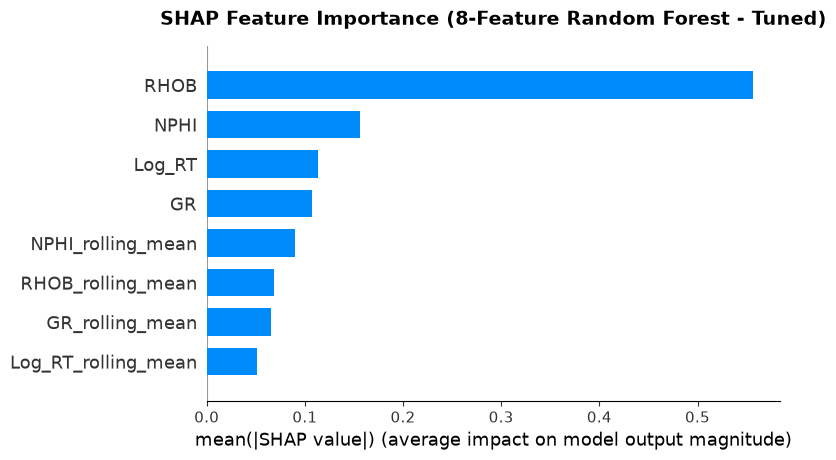

C:\Users\USER\AppData\Local\Temp\ipykernel_9412\2882812017.py:18: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_rf, X_test, feature_names=feature_cols, show=False)


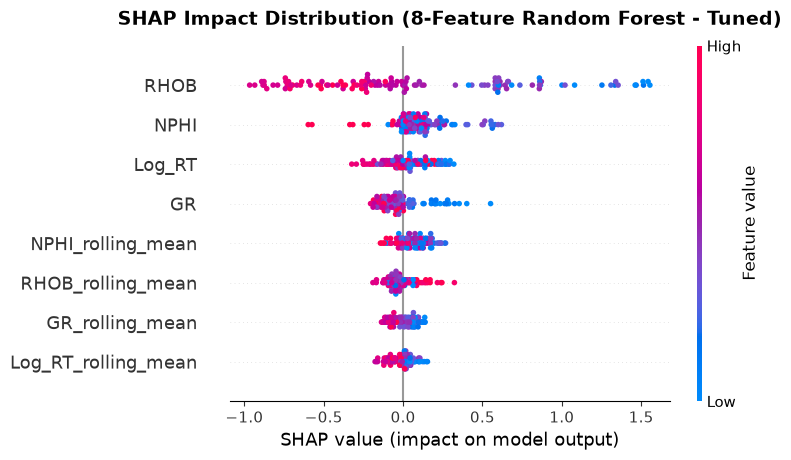

In [40]:
# === SHAP ADDITIVE FEATURE EXPLANATION (8 FEATURES - NO PPLUG) ===
import shap
import matplotlib.pyplot as plt

# 1. Initialize Tree Explainer for your Tuned Random Forest model
explainer_rf = shap.TreeExplainer(rf_tuned)
shap_values_rf = explainer_rf.shap_values(X_test)

# 2. Global Feature Importance Bar Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_rf, X_test, feature_names=feature_cols, plot_type="bar", show=False)
plt.title('SHAP Feature Importance (8-Feature Random Forest - Tuned)', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# 3. Detailed Impact Dot Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_rf, X_test, feature_names=feature_cols, show=False)
plt.title('SHAP Impact Distribution (8-Feature Random Forest - Tuned)', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

In [41]:
# === THE ULTIMATE MASTER MODEL COMPARISON TABLE ===
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score

# 1. Ensure all predictions are available
X_full_scaled = scaler.transform(df_merged[feature_cols])

# ML Predictions (Test or Full Dataset - let's use full dataset or test set consistently)
# To be rigorous, we can compute metrics across the entire evaluated dataset or test split.
# Here we use df_merged values for unified master comparison:
y_true = df_merged['Log_KPlg']

master_metrics = []

models_dict = {
    'Random Forest (Tuned)': rf_tuned.predict(X_full_scaled),
    'XGBoost (Tuned)': xgb_tuned.predict(X_full_scaled),
    'ANN (Tuned)': ann_tuned.predict(X_full_scaled).flatten(),
    'ELM (Tuned)': elm_tuned.predict(X_full_scaled),
    'Linear Regression': lr_model.predict(X_full_scaled),
    'FZI (Empirical)': df_merged['Log_Perm_FZI'],
    'Wyllie-Rose (Raw)': df_merged['Log_Perm_Wyllie'],
    'Timur (Raw)': df_merged['Log_Perm_Timur'],
    'Wyllie-Rose (Calibrated)': df_merged['Log_Perm_Wyllie_Calib']
}

for name, preds in models_dict.items():
    r2 = r2_score(y_true, preds)
    rmse = np.sqrt(mean_squared_error(y_true, preds))
    master_metrics.append({
        'Model Category': 'Machine Learning' if 'Tuned' in name or 'Regression' in name else 'Empirical Petrophysical',
        'Model Name': name,
        'R2 Score': r2,
        'RMSE (Log k)': rmse
    })

master_df = pd.DataFrame(master_metrics).sort_values(by='R2 Score', ascending=False).reset_index(drop=True)

print("=== ULTIMATE MASTER PERFORMNCE COMPARISON ===")
display(master_df.style.background_gradient(subset=['R2 Score'], cmap='Greens'))

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
=== ULTIMATE MASTER PERFORMNCE COMPARISON ===


,Model Category,Model Name,R2 Score,RMSE (Log k)
0,Machine Learning,XGBoost (Tuned),0.833108,0.495269
1,Machine Learning,Random Forest (Tuned),0.827638,0.503320
2,Machine Learning,ELM (Tuned),0.574991,0.790355
3,Empirical Petrophysical,FZI (Empirical),0.527661,0.833201
4,Machine Learning,ANN (Tuned),0.524933,0.835604
5,Empirical Petrophysical,Wyllie-Rose (Calibrated),0.311983,1.005594
6,Machine Learning,Linear Regression,0.210682,1.077083
7,Empirical Petrophysical,Timur (Raw),-0.246666,1.353625
8,Empirical Petrophysical,Wyllie-Rose (Raw),-0.466743,1.468250


In [45]:
# === RIGOROUS MASTER MODEL COMPARISON TABLE ===
# ML models evaluated strictly on Test Set (X_test, y_test)
# Empirical models evaluated on the Full Dataset (df_merged)

import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score

master_metrics = []

# 1. Machine Learning Models (Test Set Evaluation)
ml_test_preds = {
    'Random Forest (Tuned)': rf_tuned.predict(X_test),
    'XGBoost (Tuned)': xgb_tuned.predict(X_test),
    'ANN (Tuned)': ann_tuned.predict(X_test).flatten(),
    'ELM (Tuned)': elm_tuned.predict(X_test),
    'Linear Regression': lr_model.predict(X_test)
}

for name, preds in ml_test_preds.items():
    r2 = r2_score(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    master_metrics.append({
        'Model Category': 'Machine Learning (Test Set)',
        'Model Name': name,
        'R2 Score': r2,
        'RMSE (Log k)': rmse
    })

# 2. Empirical Models (Full Dataset Evaluation)
y_true_full = df_merged['Log_KPlg']

empirical_full_preds = {
    'FZI (Empirical)': df_merged['Log_Perm_FZI'],
    'Wyllie-Rose (Calibrated)': df_merged['Log_Perm_Wyllie_Calib'],
    'Wyllie-Rose (Raw)': df_merged['Log_Perm_Wyllie'],
    'Timur (Raw)': df_merged['Log_Perm_Timur']
}

for name, preds in empirical_full_preds.items():
    r2 = r2_score(y_true_full, preds)
    rmse = np.sqrt(mean_squared_error(y_true_full, preds))
    master_metrics.append({
        'Model Category': 'Empirical Petrophysical (Full Data)',
        'Model Name': name,
        'R2 Score': r2,
        'RMSE (Log k)': rmse
    })

# Combine into DataFrame and sort by R2 Score
master_comparison_df = pd.DataFrame(master_metrics).sort_values(by='R2 Score', ascending=False).reset_index(drop=True)

print("=== FINAL HYBRID MASTER PERFORMANCE COMPARISON ===")
display(master_comparison_df.style.background_gradient(subset=['R2 Score'], cmap='Greens'))

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
=== FINAL HYBRID MASTER PERFORMANCE COMPARISON ===


,Model Category,Model Name,R2 Score,RMSE (Log k)
0,Machine Learning (Test Set),Random Forest (Tuned),0.620312,0.796559
1,Machine Learning (Test Set),ELM (Tuned),0.605557,0.811888
2,Machine Learning (Test Set),XGBoost (Tuned),0.581545,0.836235
3,Machine Learning (Test Set),ANN (Tuned),0.556339,0.861052
4,Empirical Petrophysical (Full Data),FZI (Empirical),0.527661,0.833201
5,Empirical Petrophysical (Full Data),Wyllie-Rose (Calibrated),0.311983,1.005594
6,Machine Learning (Test Set),Linear Regression,0.203479,1.153726
7,Empirical Petrophysical (Full Data),Timur (Raw),-0.246666,1.353625
8,Empirical Petrophysical (Full Data),Wyllie-Rose (Raw),-0.466743,1.468250


In [47]:
import joblib

# Save your tuned Random Forest or XGBoost model
joblib.dump(rf_tuned, 'permeability_model.pkl')

# Save your fitted StandardScaler so user inputs get scaled identically
joblib.dump(scaler, 'feature_scaler.pkl')

['feature_scaler.pkl']

In [49]:
pip install streamlit

   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
    --------------------------------------- 0.3/11.2 MB ? eta -:--:--
    --------------------------------------- 0.3/11.2 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.2 MB 662.2 kB/s eta 0:00:17
   - -------------------------------------- 0.5/11.2 MB 662.2 kB/s eta 0:00:17
   -- ------------------------------------- 0.8/11.2 MB 700.3 kB/s eta 0:00:15
   -- ------------------------------------- 0.8/11.2 MB 700.3 kB/s eta 0:00:15
   --- ------------------------------------ 1.0/11.2 MB 720.2 kB/s eta 0:00:15
   ---- ----------------------------------- 1.3/11.2 MB 751.0 kB/s eta 0:00:14
   ----- ---------------------------------- 1.6/11.2 MB 781.5 kB/s eta 0:00:13
   ----- ---------------------------------- 1.6/11.2 MB 781.5 kB/s eta 0:00:13
   ------ --------------------------------- 1.8/11.2 MB 815.2 kB/s eta 0:00:12
   ------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [50]:
import streamlit as st
import numpy as np
import pandas as pd
import joblib

# Load saved model and scaler
model = joblib.load('permeability_model.pkl')
scaler = joblib.load('feature_scaler.pkl')

st.title("Well Log Permeability Predictor")
st.write("Predict formation permeability (mD) from wireline logs using machine learning.")

# User Input Widgets (Sidebar or Main Page)
st.subheader("Enter Wireline Log Values:")
gr = st.number_input("Gamma Ray (API)", value=75.0)
nphi = st.number_input("Neutron Porosity (NPHI, %)", value=20.0)
rhob = st.number_input("Bulk Density (RHOB, g/cc)", value=2.45)
log_rt = st.number_input("Log Deep Resistivity (Log Ohm.m)", value=0.8)

# If you used rolling features in your model, you can either compute them 
# dynamically or prompt for them. For a clean user experience, 
# you can default rolling features to match the point value if entering single rows:
if st.button("Predict Permeability"):
    # Create feature array (matching your 8 features)
    input_data = np.array([[gr, nphi, rhob, log_rt, gr, rhob, nphi, log_rt]])
    
    # Scale input
    input_scaled = scaler.transform(input_data)
    
    # Predict Log10(k)
    pred_log_k = model.predict(input_scaled)[0]
    
    # Convert back to actual permeability (mD)
    pred_k = 10 ** pred_log_k
    
    st.success(f"Predicted Permeability: **{pred_k:.2f} mD** (Log10 k = {pred_log_k:.2f})")

2026-11-11 23:07:12.980 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-11 23:07:13.321 
  command:

    streamlit run C:\Users\USER\AppData\Roaming\Python\Python314\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-11-11 23:07:13.322 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-11 23:07:13.323 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-11 23:07:13.324 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-11 23:07:13.325 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-11 23:07:13.327 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-11 23:07:13.327 Threa

In [51]:
%%writefile app.py
import streamlit as st
import numpy as np
import pandas as pd
import joblib

# Load saved model and scaler
model = joblib.load('permeability_model.pkl')
scaler = joblib.load('feature_scaler.pkl')

st.title("Well Log Permeability Predictor")
st.write("Predict formation permeability (mD) from wireline logs using machine learning.")

# User Input Widgets
st.subheader("Enter Wireline Log Values:")
gr = st.number_input("Gamma Ray (API)", value=75.0)
nphi = st.number_input("Neutron Porosity (NPHI, %)", value=20.0)
rhob = st.number_input("Bulk Density (RHOB, g/cc)", value=2.45)
log_rt = st.number_input("Log Deep Resistivity (Log Ohm.m)", value=0.8)

if st.button("Predict Permeability"):
    # Create feature array (matching your 8 features)
    input_data = np.array([[gr, nphi, rhob, log_rt, gr, rhob, nphi, log_rt]])
    
    # Scale input
    input_scaled = scaler.transform(input_data)
    
    # Predict Log10(k)
    pred_log_k = model.predict(input_scaled)[0]
    
    # Convert back to actual permeability (mD)
    pred_k = 10 ** pred_log_k
    
    st.success(f"Predicted Permeability: **{pred_k:.2f} mD**")

Writing app.py


In [70]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import lasio
import matplotlib.pyplot as plt
import tempfile
import os

st.title("Agjka Formation Permeability Predictor & Multi-Well Viewer")
st.write("Upload one or multiple well log files (`.las`, `.txt`, `.csv`, or `.xlsx`) to predict continuous permeability and visualize tracks.")

# Load saved model and scaler
@st.cache_resource
def load_artifacts():
    model = joblib.load('permeability_model.pkl')
    scaler = joblib.load('feature_scaler.pkl')
    return model, scaler

model, scaler = load_artifacts()

def standardize_log_columns(df):
    df.columns = [str(col).strip().upper() for col in df.columns]
    mnemonic_aliases = {
        'GR': ['GR', 'GAMMA', 'SGR', 'GRC', 'GRD', 'HSGR'],
        'NPHI': ['NPHI', 'NPH', 'NPOR', 'APTC', 'CNC', 'TNPH'],
        'RHOB': ['RHOB', 'DEN', 'RHOZ', 'ZDEN', 'HDEN', 'DRHO'],
        'RT': ['RT', 'LLD', 'ILD', 'RESD', 'AT90', 'RD'],
        'DEPT': ['DEPT', 'DEPTH', 'MD', 'TDEP']
    }
    rename_mapping = {}
    for standard_name, aliases in mnemonic_aliases.items():
        for col in df.columns:
            if col in aliases:
                rename_mapping[col] = standard_name
                break
    df = df.rename(columns=rename_mapping)
    return df

# File uploader allowing multiple files
uploaded_files = st.file_uploader(
    "Upload Well Data Files", 
    type=["las", "txt", "csv", "xlsx", "xls"],
    accept_multiple_files=True
)

if uploaded_files:
    tab_names = [file.name for file in uploaded_files]
    tabs = st.tabs(tab_names)
    
    for i, uploaded_file in enumerate(uploaded_files):
        with tabs[i]:
            file_extension = uploaded_file.name.split('.')[-1].lower()
            
            with tempfile.NamedTemporaryFile(delete=False, suffix=f'.{file_extension}') as tmp_file:
                tmp_file.write(uploaded_file.getvalue())
                tmp_path = tmp_file.name

            try:
                df = None
                if file_extension == 'las':
                    las_obj = lasio.read(tmp_path)
                    df = las_obj.df().reset_index()
                elif file_extension in ['csv', 'txt']:
                    try:
                        df = pd.read_csv(tmp_path)
                    except Exception:
                        df = pd.read_csv(tmp_path, sep='\t')
                elif file_extension in ['xlsx', 'xls']:
                    df = pd.read_excel(tmp_path)
                    
                if df is not None:
                    df = standardize_log_columns(df)
                    st.success(f"Successfully loaded: {uploaded_file.name}")
                    st.subheader("Raw Data Preview")
                    st.dataframe(df.head())
                    
                    required_cols = ['GR', 'NPHI', 'RHOB', 'RT']
                    missing_cols = [col for col in required_cols if col not in df.columns]
                    
                    if missing_cols:
                        st.warning(f"Could not automatically detect: {missing_cols}. Please map your columns manually:")
                        available_cols = list(df.columns)
                        
                        def get_default_index(target, options):
                            for idx, opt in enumerate(options):
                                if target in opt:
                                    return idx
                            return 0

                        col_gr = st.selectbox(f"Select GR for {uploaded_file.name}:", available_cols, index=get_default_index('GR', available_cols), key=f"gr_{i}")
                        col_nphi = st.selectbox(f"Select NPHI for {uploaded_file.name}:", available_cols, index=get_default_index('NPHI', available_cols), key=f"nphi_{i}")
                        col_rhob = st.selectbox(f"Select RHOB for {uploaded_file.name}:", available_cols, index=get_default_index('RHOB', available_cols), key=f"rhob_{i}")
                        col_rt = st.selectbox(f"Select RT for {uploaded_file.name}:", available_cols, index=get_default_index('RT', available_cols), key=f"rt_{i}")
                        
                        mapping_dict = {col_gr: 'GR', col_nphi: 'NPHI', col_rhob: 'RHOB', col_rt: 'RT'}
                        df_clean = df.rename(columns=mapping_dict).copy()
                    else:
                        df_clean = df.copy()

                    df_clean = df_clean.dropna(subset=required_cols).copy()
                    
                    # Convert NPHI from percentage to decimal if needed
                    if df_clean['NPHI'].max() > 1.0:
                        df_clean['NPHI'] = df_clean['NPHI'] / 100.0
                        st.info("ℹ️ NPHI curve detected in percentage units (%) and automatically converted to decimal fraction for the model.")
                    
                    if st.button(f"Run Prediction & Plot — {uploaded_file.name}", key=f"btn_{i}"):
                        # Feature Engineering matching training pipeline
                        df_clean['Log_RT'] = np.log10(df_clean['RT'].clip(lower=0.001))
                        
                        window = 5
                        df_clean['GR_rolling_mean'] = df_clean['GR'].rolling(window=window, center=True, min_periods=1).mean()
                        df_clean['NPHI_rolling_mean'] = df_clean['NPHI'].rolling(window=window, center=True, min_periods=1).mean()
                        df_clean['RHOB_rolling_mean'] = df_clean['RHOB'].rolling(window=window, center=True, min_periods=1).mean()
                        df_clean['Log_RT_rolling_mean'] = df_clean['Log_RT'].rolling(window=window, center=True, min_periods=1).mean()
                        
                        # Extract exact 8 features in correct training order
                        features_df = df_clean[[
                            'GR', 'NPHI', 'RHOB', 'Log_RT', 
                            'GR_rolling_mean', 'NPHI_rolling_mean', 'RHOB_rolling_mean', 'Log_RT_rolling_mean'
                        ]].copy()
                        
                        # Convert to NumPy array to bypass strict dataframe feature name checks
                        X_input = features_df.values
                        
                        scaled_features = scaler.transform(X_input)
                        pred_log_k = model.predict(scaled_features)
                        df_clean['PRED_PERM_mD'] = 10 ** pred_log_k
                        
                        st.subheader("Wireline Logs & Predicted Permeability Track")
                        fig, axes = plt.subplots(1, 4, figsize=(12, 8), sharey=True)
                        depth_col = df_clean.columns[0]
                        
                        axes[0].plot(df_clean['GR'], df_clean[depth_col], color='green', lw=0.8)
                        axes[0].set_title('Gamma Ray\n(API)')
                        axes[0].set_xlabel('API')
                        axes[0].invert_yaxis()
                        axes[0].grid(True)
                        
                        axes[1].plot(df_clean['RHOB'], df_clean[depth_col], color='red', lw=0.8)
                        axes[1].set_title('Bulk Density\n(g/cc)')
                        axes[1].set_xlabel('g/cc')
                        axes[1].grid(True)
                        
                        axes[2].plot(df_clean['NPHI'], df_clean[depth_col], color='blue', lw=0.8)
                        axes[2].set_title('NPHI\n(v/v)')
                        axes[2].set_xlabel('v/v')
                        axes[2].set_xlim(0.45, -0.15)
                        axes[2].grid(True)
                        
                        axes[3].plot(df_clean['PRED_PERM_mD'], df_clean[depth_col], color='purple', lw=0.8)
                        axes[3].set_title('Pred Permeability\n(mD)')
                        axes[3].set_xlabel('mD (Log)')
                        axes[3].set_xscale('log')
                        axes[3].grid(True)
                        
                        axes[0].set_ylabel('Depth')
                        plt.tight_layout()
                        st.pyplot(fig)
                        
                        csv_data = df_clean.to_csv(index=False).encode('utf-8')
                        st.download_button(
                            label=f"Download Results ({uploaded_file.name})",
                            data=csv_data,
                            file_name=f"predicted_permeability_{uploaded_file.name}.csv",
                            mime="text/csv",
                            key=f"dl_{i}"
                        )
                        
            except Exception as e:
                st.error(f"Error reading file {uploaded_file.name}: {e}")
                
            finally:
                if os.path.exists(tmp_path):
                    os.remove(tmp_path)

Overwriting app.py
